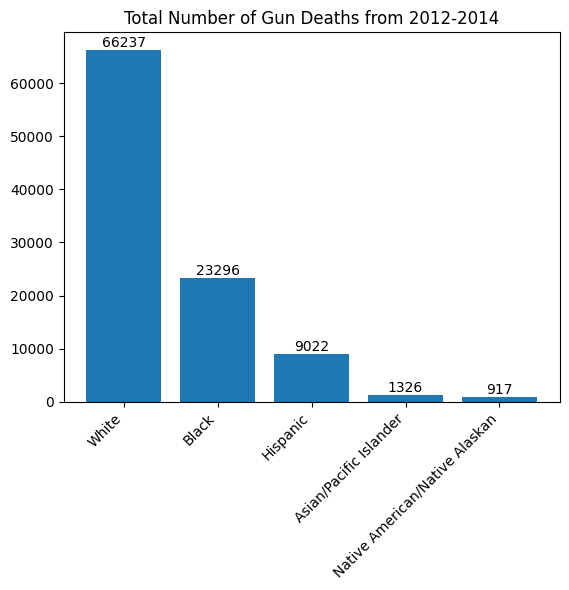

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
gun_deaths = pd.read_csv('guns.csv')
total_gun_deaths = gun_deaths.shape[0]
by_race = gun_deaths['race'].value_counts()
bars = plt.bar(by_race.index, by_race)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{bar.get_height()}', ha='center', va='bottom')
plt.xticks(rotation=45, ha='right') 
plt.title('Total Number of Gun Deaths from 2012-2014')
#plt.savefig('total_gun_deaths.png', dpi=100, bbox_inches='tight')
plt.show()

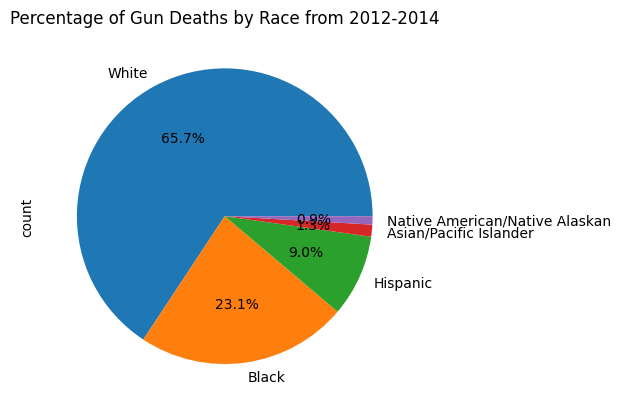

In [ ]:
by_race_percent = by_race / total_gun_deaths
plt.title('Percentage of Gun Deaths by Race from 2012-2014')
by_race_percent.plot.pie(autopct='%.1f%%')
#plt.savefig('total_gun_deaths_percent.png', dpi=100, bbox_inches='tight')
plt.show()

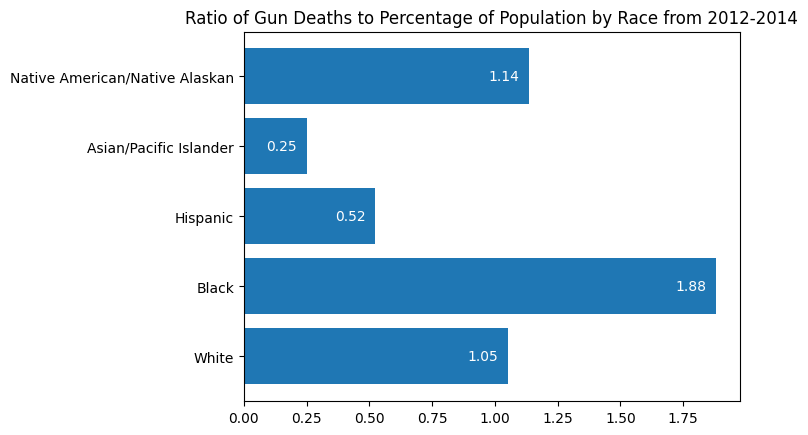

In [ ]:
#https://en.wikipedia.org/wiki/Historical_racial_and_ethnic_demographics_of_the_United_States#Historical_data_for_all_races_and_for_Hispanic_origin_(1610%E2%80%932020)
by_race_percect_adjusted_for_pop = by_race_percent / [.6244, .1228, .171, .0524, .008]
barhs = plt.barh(by_race_percect_adjusted_for_pop.index, by_race_percect_adjusted_for_pop)
for barh in barhs:
    plt.text(barh.get_width() - .1, barh.get_y() + barh.get_height() / 2,
             f'{barh.get_width():.2f}', ha='center', va='center', color='white')
plt.title('Ratio of Gun Deaths to Percentage of Population by Race from 2012-2014')
#plt.savefig('gun_deaths_ratio.png', dpi=100, bbox_inches='tight')
plt.show()

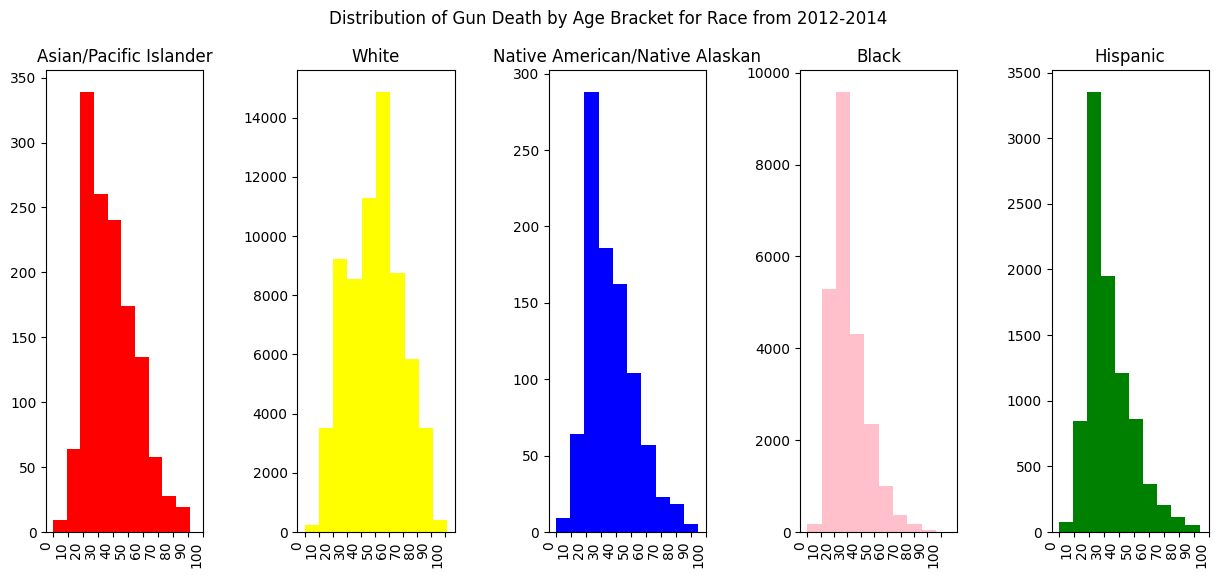

In [ ]:
by_race_age = gun_deaths[['race', 'age']]
by_race_age_data = []
races = by_race_age['race'].unique()
races_len = len(races)
for n in range(races_len):
    by_race_age_data.append(by_race_age[by_race_age['race'] == races[n]])
fig, axes = plt.subplots(nrows=1, ncols=races_len, figsize=(15,6))
colors = ['Red', 'Yellow', 'Blue', 'Pink', 'Green']
fig.suptitle('Distribution of Gun Death by Age Bracket for Race from 2012-2014')
for n in range(races_len):
    by_race_age_data_current= by_race_age_data[n]
    axes[n].hist(by_race_age_data_current['age'], bins=10, color=colors[n])
    axes[n].set_title(races[n])
    axes[n].set_xticks(np.arange(0, 101, 10))
    axes[n].set_xticklabels(np.arange(0, 101, 10), rotation=90, ha='right')
plt.subplots_adjust(wspace=0.6)
#plt.savefig('gun_death_age.png', dpi=100, bbox_inches='tight')
plt.show()

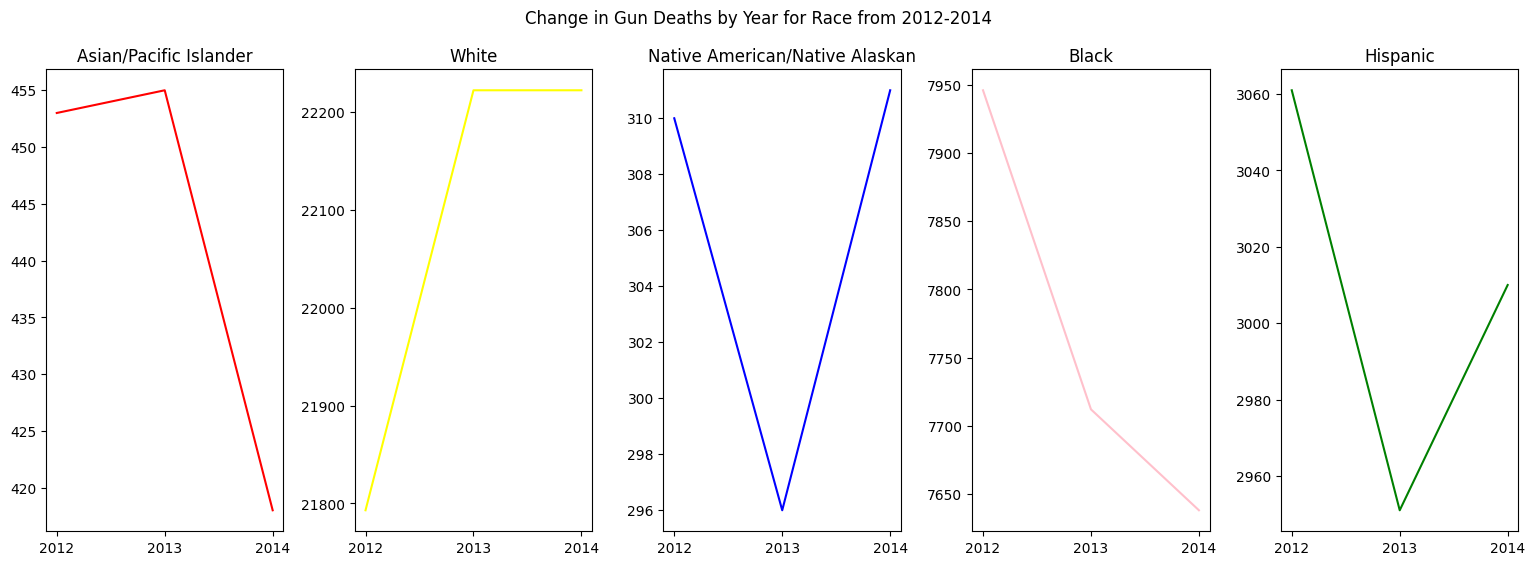

In [ ]:
by_race_year = gun_deaths[['race', 'year']]
fig, axes = plt.subplots(nrows=1, ncols=races_len, figsize=(19,6))
fig.suptitle('Change in Gun Deaths by Year for Race from 2012-2014')
for n in range(races_len):
    by_race_year_data = by_race_year[by_race_year['race'] == races[n]].value_counts()
    by_race_year_data = by_race_year_data.sort_index()
    axes[n].plot(by_race_year_data.loc[races[n]].index, by_race_year_data.loc[races[n]].values, color=colors[n])
    axes[n].set_title(races[n])
    axes[n].set_xticks([2012, 2013, 2014])
plt.subplots_adjust(wspace=0.3)
#plt.savefig('gun_death_change.png', dpi=100, bbox_inches='tight')
plt.show()

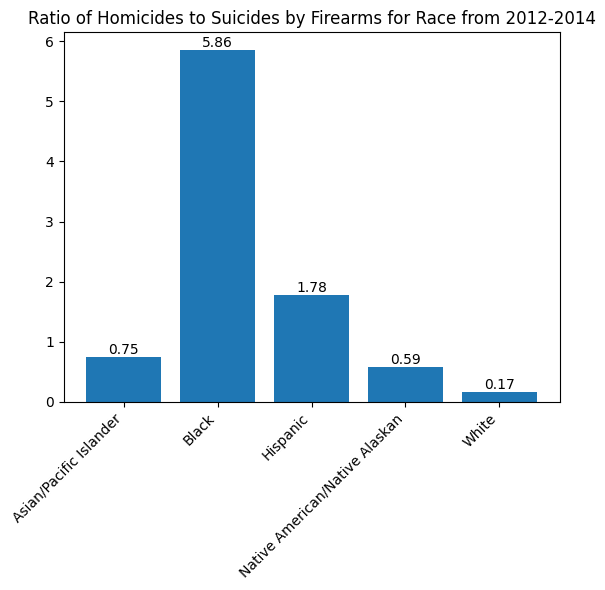

In [ ]:
by_race_intent = gun_deaths[['race', 'intent']]
homicides = by_race_intent[by_race_intent['intent'] == 'Homicide'].value_counts()
suicides = by_race_intent[by_race_intent['intent'] == 'Suicide'].value_counts()
homicides = homicides.sort_index()
suicides = suicides.sort_index()
h_to_s_ratio = homicides.values / suicides.values
bars = plt.bar(homicides.index.levels[0], h_to_s_ratio)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{bar.get_height():.2f}', ha='center', va='bottom')
plt.xticks(rotation=45, ha='right')
plt.title("Ratio of Homicides to Suicides by Firearms for Race from 2012-2014") 
#plt.savefig('h_to_s_ratio.png', dpi=100, bbox_inches='tight')
plt.show()